# Multilayer perceptron: train and evaluate on the final 10K dataset

Preferred model: 5 → 128 → 64 → 32 → 3; SiLU, dropout 0.05, positive normalized outputs.

This notebook trains from the CSV using the frozen **7,000 training / 1,500 validation / 1,500 test** plant split. It needs no model archive or saved checkpoint. All fitted models, predictions and new results stay in memory; figures and tables are notebook outputs only.

The settings below are the published study's preselected settings. This is a reconstruction of that workflow, not a fresh hyperparameter search or a new independent performance claim. Do not change settings in response to the test results. Floating-point differences and timings can vary across machines.

In [1]:
import os
# Limit nested numerical-library threads before importing scientific packages.
for variable in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[variable] = '1'
from pathlib import Path
import sys, json, hashlib, tempfile
from time import perf_counter
from concurrent.futures import ProcessPoolExecutor
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'mlpid-notebook-mpl'))
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/data_gen.py').is_file())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
from benchmark import FEATURES, TARGETS, PLANT_COLUMNS, load_frame, gain_metrics
from target_normalization import evaluate_task
from data_gen import Plant, PIDGains, PlantSimulator
JOBS = min(4, os.cpu_count() or 1)  # Set to 1 to use serial simulation.
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})

E:\projects\ML-PID\.venv-review\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
MODEL_NAME = 'standard_mlp'

## Load and verify the fixed split
The same plant rows are used by all six model notebooks. Physical parameters are audit/simulation metadata; only the five empirical features enter the model.

In [3]:
FINAL = ROOT / 'results/dataset_final_10000'
protocol = json.loads((FINAL / 'evaluation_protocol.json').read_text())
data_path = ROOT / protocol['data_path']
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == protocol['dataset_sha256']
frame = load_frame(data_path)
train, validation, test = [protocol[key] for key in ('train', 'validation', 'test')]
assert len(frame) == 10000 and [len(train), len(validation), len(test)] == [7000, 1500, 1500]
assert not (set(train) & set(validation) or set(train) & set(test) or set(validation) & set(test))
assert len(set(train) | set(validation) | set(test)) == 10000
assert not frame.duplicated(PLANT_COLUMNS).any()
X_train, X_val, X_test = [frame.loc[indices, FEATURES] for indices in (train, validation, test)]
y_train, y_val, y_test = [frame.loc[indices, TARGETS].to_numpy() for indices in (train, validation, test)]
display(pd.DataFrame({'partition': ['Training', 'Validation', 'Test'], 'plants': [len(train), len(validation), len(test)],
                      'zero_delay': [int(frame.loc[indices, 'tau'].eq(0).sum()) for indices in (train, validation, test)]}))

,partition,plants,zero_delay
0,Training,7000,719
1,Validation,1500,154
2,Test,1500,154


## Normalize controller-gain targets

Use measured final output $y_{ss}$ and rise time $t_r$:

$$q_p=y_{ss}K_p,\qquad q_i=y_{ss}t_rK_i,\qquad q_d=\frac{y_{ss}K_d}{t_r}.$$

Training statistics and any feature scaling are fitted on training rows only. Decode predictions back to physical PID gains before checking a controller. No clipping or fallback controller is applied.

In [4]:
def target_factors(features):
    values = np.asarray(features, dtype=float)
    rise, final = values[:, 0], values[:, 3]
    assert np.all(rise > 0) and np.all(final > 0)
    return np.column_stack([final, final * rise, final / rise])

q_train = y_train * target_factors(X_train)
display(pd.DataFrame(q_train, columns=['q_p', 'q_i', 'q_d']).describe().loc[['min', '50%', 'max']])

,q_p,q_i,q_d
min,0.054746,0.117231,0.000250
50%,0.891303,1.344526,0.233759
max,5.526666,11.543975,2.959721


## Construct and fit the selected model
Preferred model: 5 → 128 → 64 → 32 → 3; SiLU, dropout 0.05, positive normalized outputs.

In [5]:
from MLP import MLPModel
model = MLPModel(hidden_dims=(128, 64, 32), dropout=0.05, weight_decay=0.0001, beta=0, lr=0.001, max_epochs=500, patience=50, batch_size=256, seed=42, device="cpu")

MLP epoch 25: train loss=0.09492, validation loss=0.09270


MLP epoch 50: train loss=0.06451, validation loss=0.06301


MLP epoch 75: train loss=0.05309, validation loss=0.05303


MLP epoch 100: train loss=0.04774, validation loss=0.04503


MLP epoch 125: train loss=0.04292, validation loss=0.03869


MLP epoch 150: train loss=0.03453, validation loss=0.03371


... (12 outputs left out)

MLP epoch 475: train loss=0.02015, validation loss=0.01949


MLP epoch 500: train loss=0.01844, validation loss=0.01728


Fit seconds: 23.74839609999981 | best validation epoch: 471


,epoch,train_loss,val_loss,train_supervised,val_supervised,train_stability,val_stability
495,496,0.019572,0.019126,0.019572,0.019126,0.0,0.0
496,497,0.020097,0.017678,0.020097,0.017678,0.0,0.0
497,498,0.018988,0.017079,0.018988,0.017079,0.0,0.0
498,499,0.019388,0.016766,0.019388,0.016766,0.0,0.0
499,500,0.018437,0.017278,0.018437,0.017278,0.0,0.0


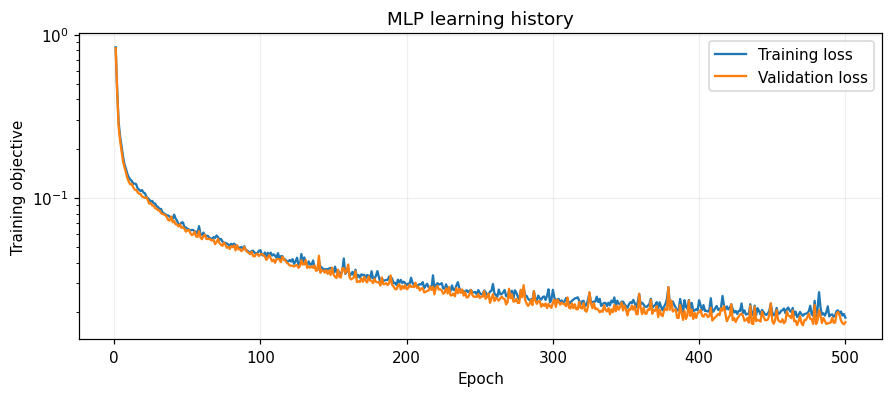

In [6]:
started = perf_counter()
# Validation controls early stopping; test rows never enter training.
model.fit(X_train, y_train, validation_data=(X_val, y_val, None))
print('Fit seconds:', perf_counter() - started, '| best validation epoch:', model.best_epoch)
def predict_gains(features):
    return model.predict(features)
history = pd.DataFrame(model.history)
display(history.tail())
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
ax.plot(history.epoch, history.train_loss, label='Training loss')
ax.plot(history.epoch, history.val_loss, label='Validation loss')
ax.set(xlabel='Epoch', ylabel='Training objective', title='MLP learning history', yscale='log')
ax.legend(); plt.show()

## Gain-regression validation
Report MAE, RMSE and R² on validation and test rows. The test plots include every predicted gain, including negative predictions. Gain agreement alone does not establish a good controller.

,Kp_mae,Kp_rmse,Kp_r2,Ki_mae,Ki_rmse,Ki_r2,Kd_mae,Kd_rmse,Kd_r2,r2
Validation,0.062244,0.148598,0.990889,0.177619,0.485312,0.988280,0.034437,0.134529,0.938206,0.972458
Test,0.062899,0.193354,0.984023,0.165383,0.446052,0.988556,0.033747,0.090914,0.965624,0.979401


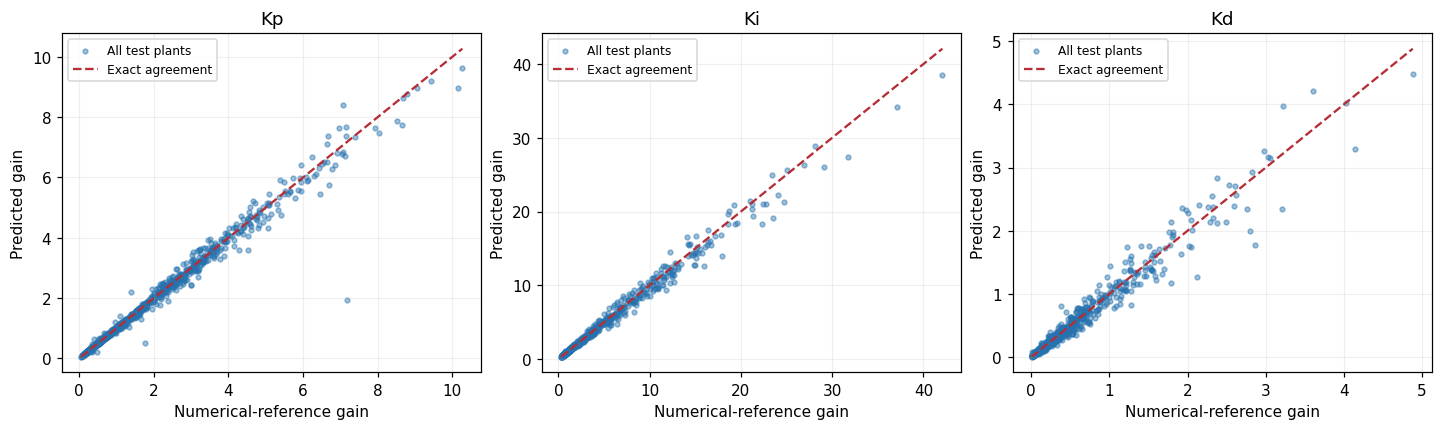

In [7]:
validation_gains = predict_gains(X_val)
test_gains = predict_gains(X_test)
assert test_gains.shape == (1500, 3) and np.isfinite(test_gains).all()
metrics = pd.DataFrame([gain_metrics(y_val, validation_gains), gain_metrics(y_test, test_gains)], index=['Validation', 'Test'])
display(metrics)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')
for j, ax in enumerate(axes):
    actual, predicted = y_test[:, j], test_gains[:, j]
    lo, hi = min(actual.min(), predicted.min()), max(actual.max(), predicted.max())
    ax.scatter(actual, predicted, s=10, alpha=0.45, color='#2672ae', label='All test plants')
    ax.plot([lo, hi], [lo, hi], '--', color='#b62d34', label='Exact agreement')
    ax.set(xlabel='Numerical-reference gain', ylabel='Predicted gain', title=TARGETS[j])
    ax.legend(fontsize=8)
plt.show()

## Independently simulate all 1,500 predicted test controllers

This cell can take several minutes. It uses the original ideal-PID, second-order Padé evaluator and unit setpoint. Each controller is checked for finite bounded gains, stable poles, at most 10% overshoot, tail convergence and numerical refinement. The objective is normalized ITAE plus the dimensionless gain penalty with λ = 0.01. Numerical-reference metrics come from the same test plants' validated generator labels, not a new optimization.

The 10% limit stays fixed. A stable overshoot miss is a specification violation, not evidence that the controller is useless. ITAE/J ratios below include only pairs passing the strict checks; coverage is shown. Set `JOBS = 1` in the setup cell if process workers are unavailable.

In [8]:
# The shared evaluator includes bounds, poles, overshoot and numerical-convergence checks.
# It is a module-level function, so multiprocessing also works on Windows.
tasks = [(int(i), frame.loc[i, PLANT_COLUMNS].tolist(), gains.tolist(), 0.01)
         for i, gains in zip(test, test_gains)]
started = perf_counter()
if JOBS == 1:
    records = list(tqdm(map(evaluate_task, tasks), total=len(tasks), mininterval=5))
else:
    with ProcessPoolExecutor(max_workers=JOBS) as pool:
        records = list(tqdm(pool.map(evaluate_task, tasks, chunksize=8), total=len(tasks), mininterval=5))
results = pd.DataFrame(records)
assert results.source_row.tolist() == test
reference = pd.read_csv(FINAL / 'test_references.csv').set_index('source_row').loc[test].reset_index()
assert reference.source_row.tolist() == test
results['reference_accepted'] = reference.accepted.to_numpy()
paired = results.accepted & results.reference_accepted
results['itae_ratio'] = np.where(paired, results.itae / reference.itae.to_numpy(), np.nan)
results['objective_ratio'] = np.where(paired, results.objective / reference.objective.to_numpy(), np.nan)
summary = pd.Series({'plants': len(results), 'strict_passes': int(results.accepted.sum()),
    'strict_acceptance_pct': 100 * results.accepted.mean(), 'stable_pct': 100 * results.stable.mean(),
    'accepted_ratio_pairs': int(paired.sum()), 'median_accepted_ITAE_ratio': results.itae_ratio.median(),
    'median_accepted_J_ratio': results.objective_ratio.median(), 'simulation_seconds': perf_counter() - started})
display(summary.to_frame('Retrained model'))
display(results.reason.value_counts().rename_axis('Outcome').to_frame('Plants'))

  0%|          | 0/1500 [00:00<?, ?it/s]

  9%|▊         | 129/1500 [00:05<00:56, 24.19it/s]

 20%|█▉        | 297/1500 [00:10<00:40, 29.43it/s]

 32%|███▏      | 481/1500 [00:16<00:33, 30.79it/s]

 43%|████▎     | 641/1500 [00:22<00:29, 28.75it/s]

 43%|████▎     | 641/1500 [00:40<00:29, 28.75it/s]

... (7 outputs left out)

 90%|█████████ | 1353/1500 [01:33<00:07, 19.10it/s]

100%|██████████| 1500/1500 [01:37<00:00, 15.39it/s]

,Retrained model
plants,1500.000000
strict_passes,1406.000000
strict_acceptance_pct,93.733333
stable_pct,100.000000
accepted_ratio_pairs,1406.000000
median_accepted_ITAE_ratio,1.057748
median_accepted_J_ratio,1.057760
simulation_seconds,97.742283


,Plants
Outcome,
accepted,1406
overshoot,94


## Understand controller failures and tracking cost
Unstable or unresolved responses stay in the denominator. Missing overshoot measurements are counted explicitly. An ITAE ratio above one means slower tracking than that plant’s numerical-reference controller; lower is better.

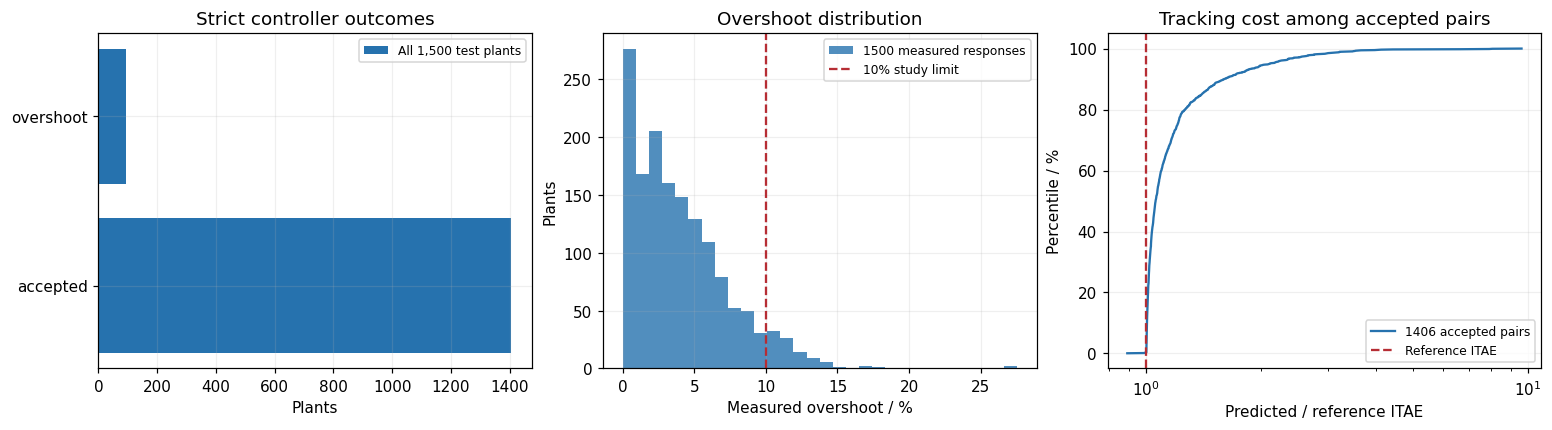

Unmeasured overshoot responses: 0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), layout='constrained')
counts = results.reason.value_counts()
axes[0].barh(counts.index.str.replace('_', ' '), counts, color='#2672ae', label='All 1,500 test plants')
axes[0].set(xlabel='Plants', title='Strict controller outcomes'); axes[0].legend(fontsize=8)
overshoot = results.overshoot_pct.dropna()
axes[1].hist(overshoot, bins=30, color='#2672ae', alpha=0.8, label=f'{len(overshoot)} measured responses')
axes[1].axvline(10, color='#b62d34', ls='--', label='10% study limit')
axes[1].set(xlabel='Measured overshoot / %', ylabel='Plants', title='Overshoot distribution'); axes[1].legend(fontsize=8)
ratios = np.sort(results.itae_ratio.dropna().to_numpy())
ratios = ratios[ratios > 0]
if len(ratios):
    axes[2].plot(ratios, 100 * np.arange(1, len(ratios) + 1) / len(ratios), color='#2672ae', label=f'{len(ratios)} accepted pairs')
    axes[2].set_xscale('log')
axes[2].axvline(1, color='#b62d34', ls='--', label='Reference ITAE')
axes[2].set(xlabel='Predicted / reference ITAE', ylabel='Percentile / %', title='Tracking cost among accepted pairs'); axes[2].legend(fontsize=8)
plt.show()
print('Unmeasured overshoot responses:', int(results.overshoot_pct.isna().sum()))

## Inspect two fixed response examples
These plots use the first two test plants rather than cherry-picking successful predictions. Their shortened display windows and sampled curves do not replace the full validation above. Extreme/nonfinite predicted traces are explicitly omitted for readability.

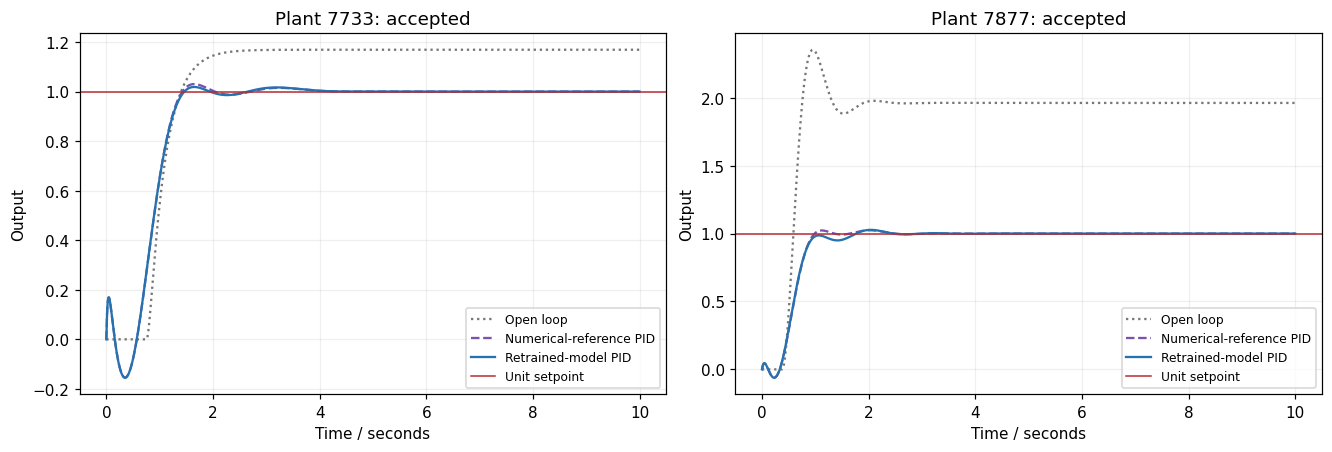

In [10]:
simulator = PlantSimulator()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
# Fixed first two test rows: selected independently of whether prediction succeeds.
for ax, position in zip(axes, [0, 1]):
    row = frame.loc[test[position]]
    plant = Plant(row.zeta, row.wn, row.tau, row.K)
    duration = min(30, max(5, float(simulator.get_dynamic_t_eval(plant)[-1])))
    times = np.linspace(0, duration, 1500)
    _, open_output = simulator.open_loop(plant, times)
    _, reference_output = simulator.close_loop(plant, PIDGains(*y_test[position]), times)
    ax.plot(times, open_output, ':', color='#777777', label='Open loop')
    ax.plot(times, reference_output, '--', color='#7852ad', label='Numerical-reference PID')
    try:
        _, predicted_output = simulator.close_loop(plant, PIDGains(*test_gains[position]), times)
        if np.isfinite(predicted_output).all() and np.max(np.abs(predicted_output)) <= 5:
            ax.plot(times, predicted_output, color='#2672ae', label='Retrained-model PID')
        else:
            ax.text(0.03, 0.1, 'Predicted trace omitted: nonfinite or exceeds display range', transform=ax.transAxes, fontsize=8)
    except (ValueError, FloatingPointError):
        ax.text(0.03, 0.1, 'Predicted trace could not be plotted', transform=ax.transAxes, fontsize=8)
    ax.axhline(1, color='#b62d34', lw=1, label='Unit setpoint')
    ax.set(xlabel='Time / seconds', ylabel='Output', title=f'Plant {test[position]}: {results.iloc[position].reason}')
    ax.legend(fontsize=8)
plt.show()

## Compare this reconstruction with the published frozen study
The saved table below is context, not a target for test-set retuning. This notebook does not change it or the model used by the website.

In [11]:
published = pd.read_csv(FINAL / 'test_metrics.csv').set_index('model').loc[MODEL_NAME]
display(pd.DataFrame({'Published frozen study': [published.success_pct, published.r2, published.median_ITAE_ratio],
                      'This notebook': [summary.strict_acceptance_pct, metrics.loc['Test', 'r2'], summary.median_accepted_ITAE_ratio]},
                     index=['Strict acceptance / %', 'Gain R²', 'Median accepted ITAE ratio']))
print('No model checkpoints, CSVs or external figures were saved. Use Save Notebook to retain these cell outputs.')

,Published frozen study,This notebook
Strict acceptance / %,93.733333,93.733333
Gain R²,0.979401,0.979401
Median accepted ITAE ratio,1.057748,1.057748


No model checkpoints, CSVs or external figures were saved. Use Save Notebook to retain these cell outputs.
